In [1]:
# If running in Colab, seaborn is usually pre-installed. Uncomment if needed.
# !pip install seaborn matplotlib pandas -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
%matplotlib inline
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['figure.dpi'] = 100

print("Libraries loaded successfully ✅")

Libraries loaded successfully ✅


In [2]:
# Load the dataset built into seaborn
tips = sns.load_dataset("tips")

print("Shape:", tips.shape)
tips.head()

Shape: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


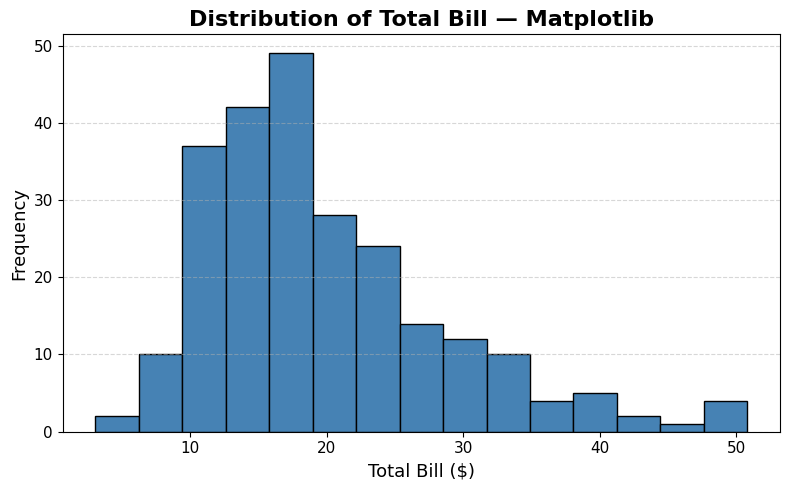

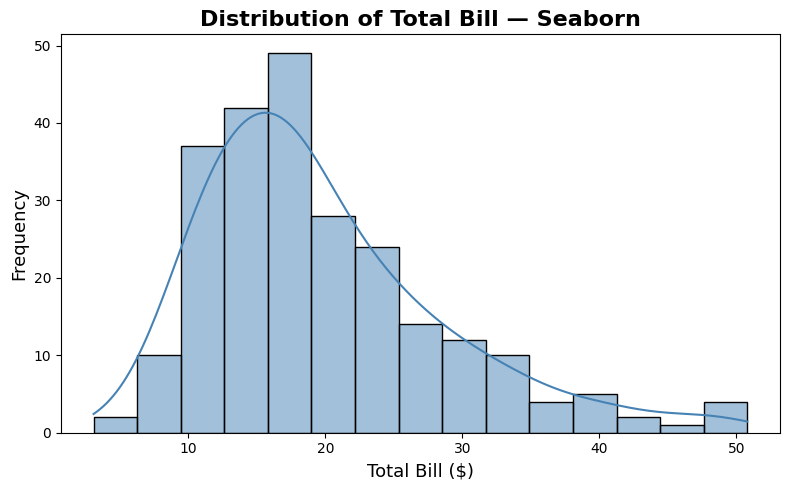

In [3]:
# ---------- Matplotlib Histogram ----------
plt.figure(figsize=(8, 5))
plt.hist(tips['total_bill'], bins=15, color='steelblue', edgecolor='black')
plt.title("Distribution of Total Bill — Matplotlib", fontsize=16, fontweight='bold')
plt.xlabel("Total Bill ($)", fontsize=13)
plt.ylabel("Frequency", fontsize=13)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# ---------- Seaborn Histogram ----------
plt.figure(figsize=(8, 5))
sns.histplot(data=tips, x='total_bill', bins=15,
             color='steelblue', edgecolor='black', kde=True)
plt.title("Distribution of Total Bill — Seaborn", fontsize=16, fontweight='bold')
plt.xlabel("Total Bill ($)", fontsize=13)
plt.ylabel("Frequency", fontsize=13)
plt.tight_layout()
plt.show()

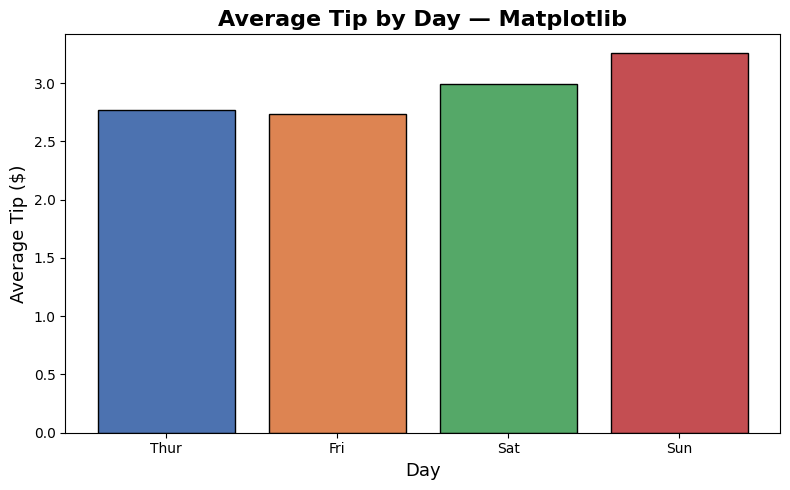

/tmp/ipykernel_2116/4054859693.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tips, x='day', y='tip', estimator=np.mean,


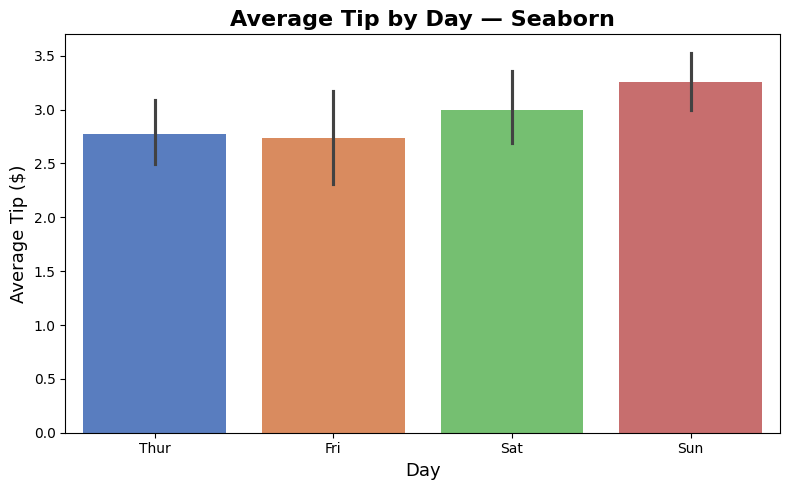

In [4]:
# Prepare grouped data (pandas)
avg_tip_by_day = tips.groupby('day', observed=True)['tip'].mean().reset_index()

# ---------- Matplotlib Bar Chart ----------
plt.figure(figsize=(8, 5))
plt.bar(avg_tip_by_day['day'], avg_tip_by_day['tip'],
        color=['#4C72B0', '#DD8452', '#55A868', '#C44E52'], edgecolor='black')
plt.title("Average Tip by Day — Matplotlib", fontsize=16, fontweight='bold')
plt.xlabel("Day", fontsize=13)
plt.ylabel("Average Tip ($)", fontsize=13)
plt.tight_layout()
plt.show()

# ---------- Seaborn Bar Chart ----------
plt.figure(figsize=(8, 5))
sns.barplot(data=tips, x='day', y='tip', estimator=np.mean,
            palette='muted', errorbar='ci')
plt.title("Average Tip by Day — Seaborn", fontsize=16, fontweight='bold')
plt.xlabel("Day", fontsize=13)
plt.ylabel("Average Tip ($)", fontsize=13)
plt.tight_layout()
plt.show()

/tmp/ipykernel_2116/964940746.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_by_day, labels=days, patch_artist=True,


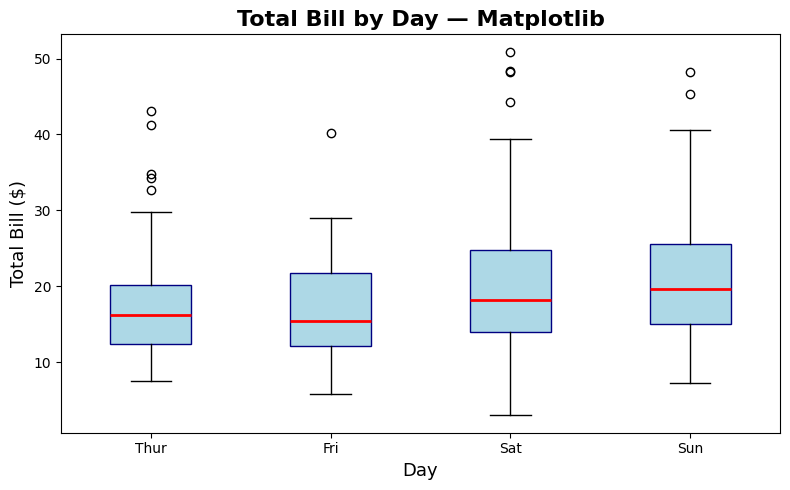

/tmp/ipykernel_2116/964940746.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=tips, x='day', y='total_bill',


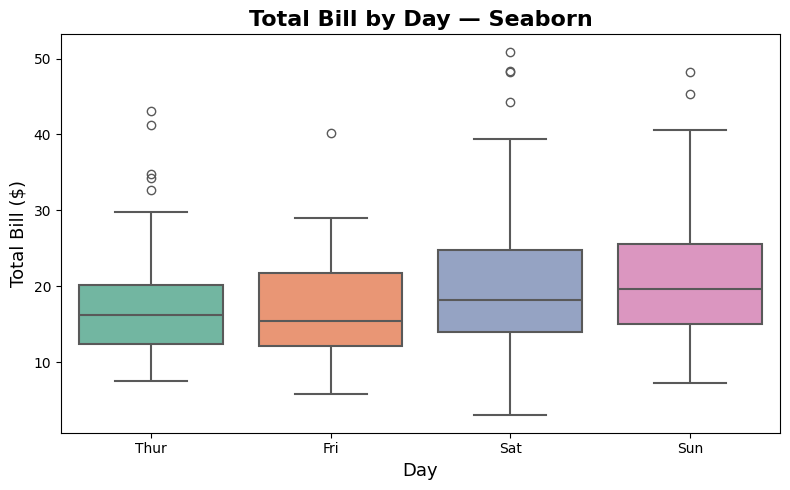

In [5]:
# ---------- Matplotlib Box Plot ----------
days = tips['day'].cat.categories
data_by_day = [tips.loc[tips['day'] == d, 'total_bill'] for d in days]

plt.figure(figsize=(8, 5))
plt.boxplot(data_by_day, labels=days, patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='navy'),
            medianprops=dict(color='red', linewidth=2))
plt.title("Total Bill by Day — Matplotlib", fontsize=16, fontweight='bold')
plt.xlabel("Day", fontsize=13)
plt.ylabel("Total Bill ($)", fontsize=13)
plt.tight_layout()
plt.show()

# ---------- Seaborn Box Plot ----------
plt.figure(figsize=(8, 5))
sns.boxplot(data=tips, x='day', y='total_bill',
            palette='Set2', linewidth=1.5)
plt.title("Total Bill by Day — Seaborn", fontsize=16, fontweight='bold')
plt.xlabel("Day", fontsize=13)
plt.ylabel("Total Bill ($)", fontsize=13)
plt.tight_layout()
plt.show()

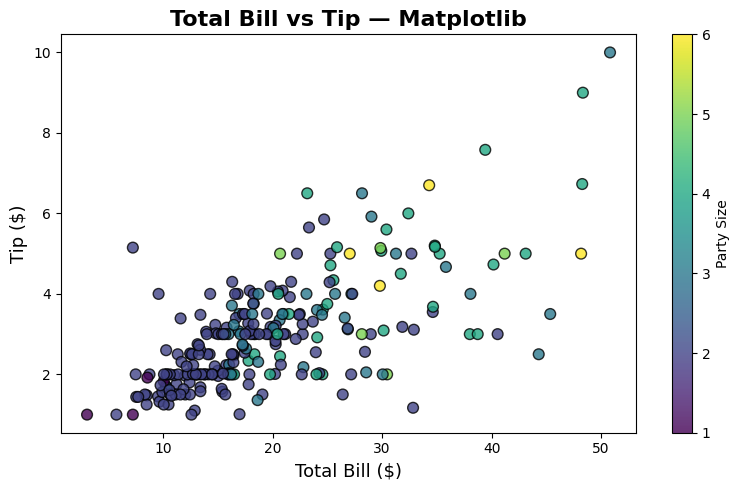

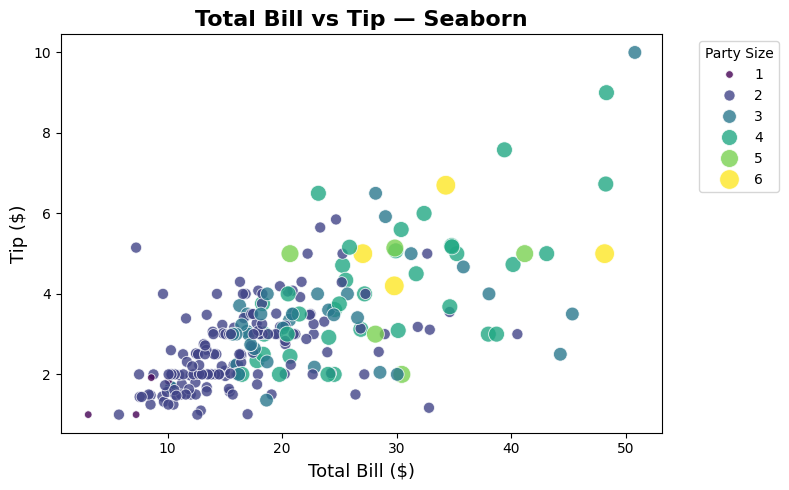

In [6]:
# ---------- Matplotlib Scatter ----------
plt.figure(figsize=(8, 5))
scatter = plt.scatter(tips['total_bill'], tips['tip'],
                      c=tips['size'], cmap='viridis',
                      s=60, alpha=0.8, edgecolor='k')
plt.colorbar(scatter, label='Party Size')
plt.title("Total Bill vs Tip — Matplotlib", fontsize=16, fontweight='bold')
plt.xlabel("Total Bill ($)", fontsize=13)
plt.ylabel("Tip ($)", fontsize=13)
plt.tight_layout()
plt.show()

# ---------- Seaborn Scatter ----------
plt.figure(figsize=(8, 5))
sns.scatterplot(data=tips, x='total_bill', y='tip',
                hue='size', size='size',
                palette='viridis', alpha=0.8, sizes=(30, 200))
plt.title("Total Bill vs Tip — Seaborn", fontsize=16, fontweight='bold')
plt.xlabel("Total Bill ($)", fontsize=13)
plt.ylabel("Tip ($)", fontsize=13)
plt.legend(title='Party Size', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

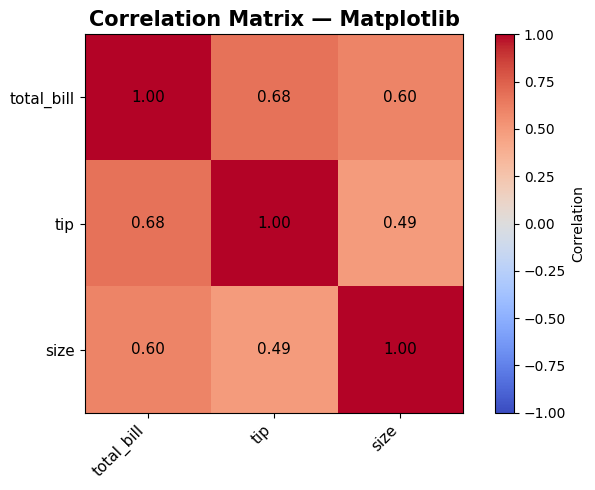

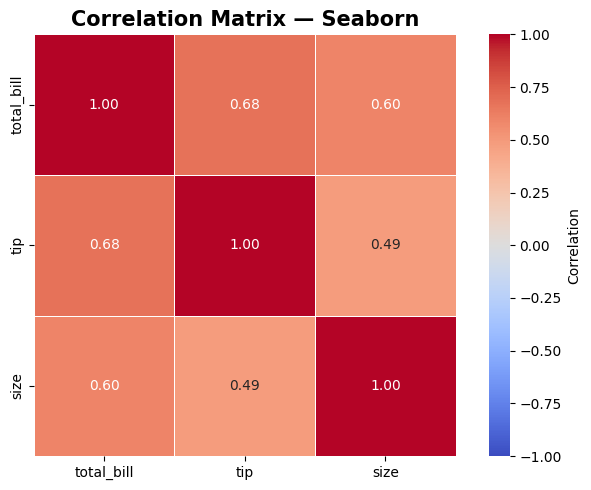

✅ Saved: correlation_heatmap_seaborn.png


In [7]:
# Compute correlation matrix (numeric columns only)
corr = tips.select_dtypes(include='number').corr()

# ---------- Matplotlib Heatmap (via imshow) ----------
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)

# Annotate each cell
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}",
                ha='center', va='center', color='black', fontsize=11)

ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha='right', fontsize=11)
ax.set_yticklabels(corr.index, fontsize=11)
ax.set_title("Correlation Matrix — Matplotlib", fontsize=15, fontweight='bold')
fig.colorbar(im, ax=ax, label='Correlation')
plt.tight_layout()
plt.show()

# ---------- Seaborn Heatmap ----------
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, linewidths=0.5, square=True,
            cbar_kws={'label': 'Correlation'})
plt.title("Correlation Matrix — Seaborn", fontsize=15, fontweight='bold')
plt.tight_layout()

# Save this chart as PNG
plt.savefig("correlation_heatmap_seaborn.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved: correlation_heatmap_seaborn.png")

/tmp/ipykernel_2116/550378228.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tips, x='day', y='tip', estimator=np.mean, ax=axes[1], palette='muted')
/tmp/ipykernel_2116/550378228.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=tips, x='day', y='total_bill', ax=axes[2], palette='Set2')


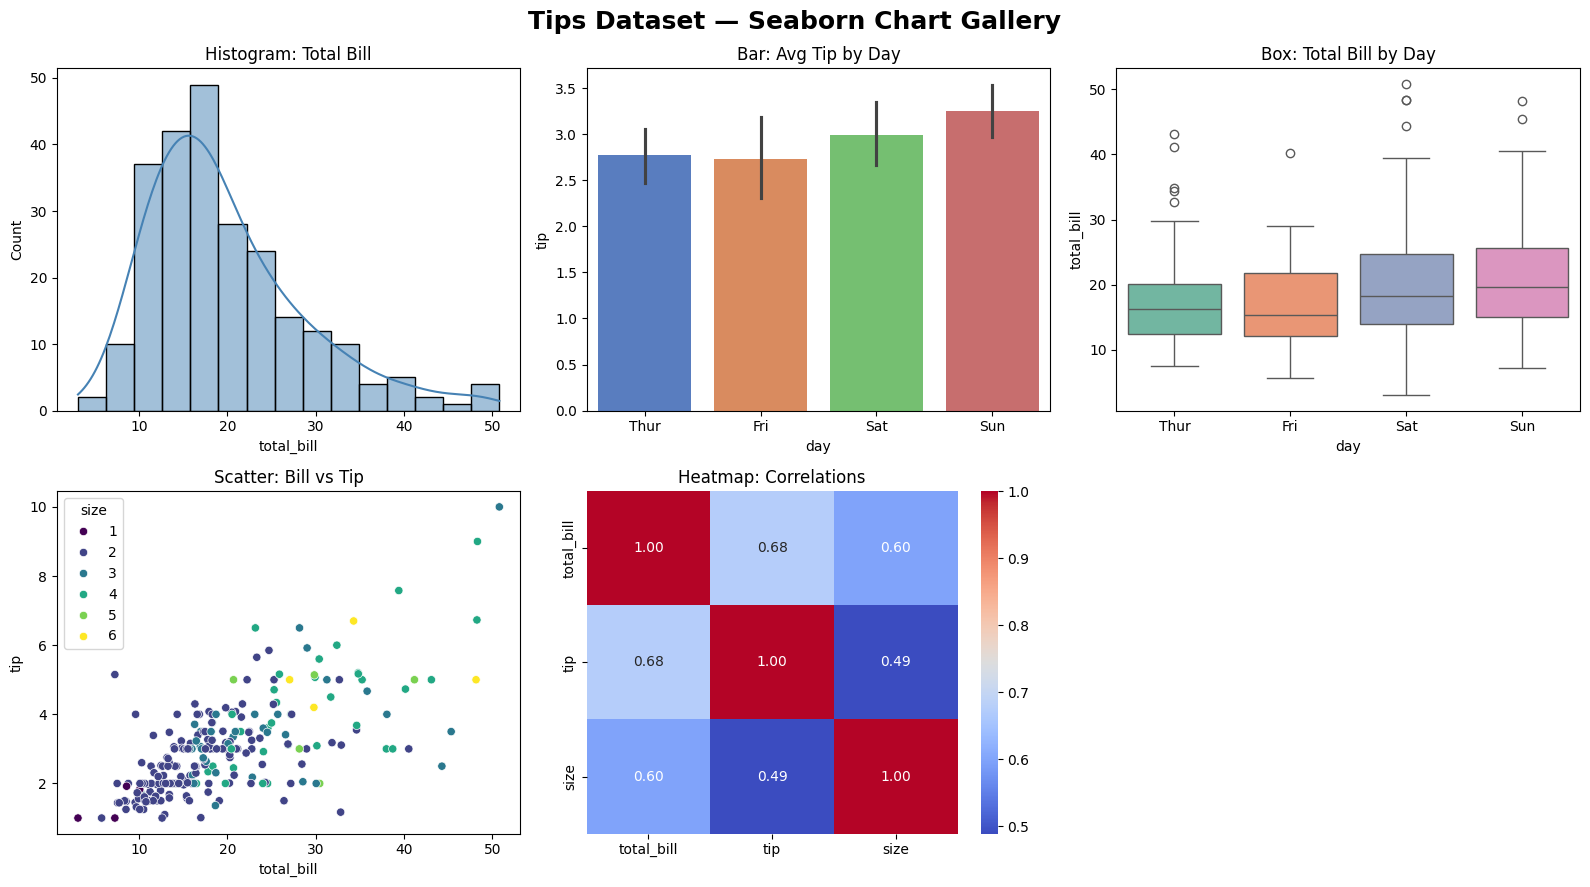

✅ Saved: tips_gallery.png


In [8]:
# Save a combined figure showing all 5 Seaborn charts to compare at a glance
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

sns.histplot(tips['total_bill'], bins=15, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title("Histogram: Total Bill")

sns.barplot(data=tips, x='day', y='tip', estimator=np.mean, ax=axes[1], palette='muted')
axes[1].set_title("Bar: Avg Tip by Day")

sns.boxplot(data=tips, x='day', y='total_bill', ax=axes[2], palette='Set2')
axes[2].set_title("Box: Total Bill by Day")

sns.scatterplot(data=tips, x='total_bill', y='tip', hue='size', ax=axes[3], palette='viridis')
axes[3].set_title("Scatter: Bill vs Tip")

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[4])
axes[4].set_title("Heatmap: Correlations")

axes[5].axis('off')  # leave one empty

fig.suptitle("Tips Dataset — Seaborn Chart Gallery", fontsize=18, fontweight='bold')
plt.tight_layout()
plt.savefig("tips_gallery.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved: tips_gallery.png")